==== Estado Inicial (Perceptrón para OR) ====
w₁ = 0.356, w₂ = 0.259, b = 0.122, lr = 0.050

=== Paso 1: Ejemplo (x₁=0, x₂=0) → y=0 (OR) ===
z = w₁·x₁ + w₂·x₂ + b = 0.356·0 + 0.259·0 + 0.122 = 0.122
Salida predicha: Φ(z) = 1
Error: e = y_true - y_pred = 0 - 1 = -1

→ Actualización de parámetros:
w₁: 0.356 → 0.356
w₂: 0.259 → 0.259
b : 0.122 → 0.072  (¡no cambian los pesos porque x=(0,0)! Solo cambia el bias)


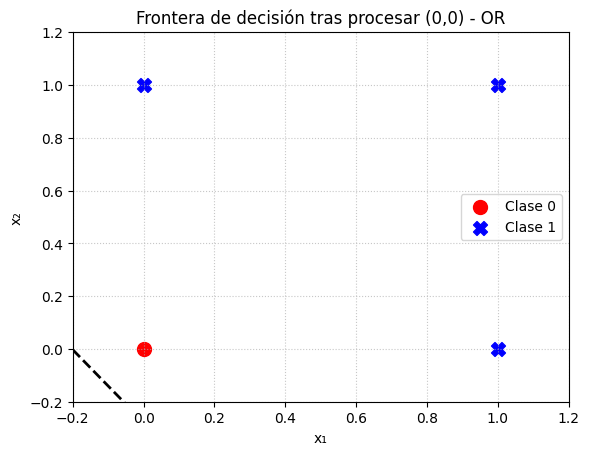

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def step(Z):
    return 1 if Z >= 0 else 0  # Función de activación escalón (Heaviside)

# Dataset OR
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([0, 1, 1, 1], dtype=float)  # Tabla de verdad del OR

class Perceptron:
    def __init__(self, w1=0.356, w2=0.259, b=0.122, lr=0.05):
        self.w = np.array([w1, w2], dtype=float)
        self.b = float(b)
        self.lr = float(lr)

    def predict(self, x):
        z = float(np.dot(self.w, x) + self.b)
        return step(z), z

    def update(self, x, y_true):
        y_pred, z = self.predict(x)
        err = float(y_true - y_pred)
        self.w = self.w + self.lr * err * x
        self.b = self.b + self.lr * err
        return y_pred, z, err

def plot_boundary(p, X, y, title=""):
    # Colores y marcadores para clases
    for i in range(len(X)):
        if y[i] == 0:
            plt.scatter(X[i,0], X[i,1], color='red', marker='o', s=100, label='Clase 0' if i == 0 else "")
        else:
            plt.scatter(X[i,0], X[i,1], color='blue', marker='X', s=100, label='Clase 1' if i == 1 else "")

    # Evitar leyendas duplicadas
    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys())

    # Dibujar frontera de decisión: w1*x1 + w2*x2 + b = 0 → x2 = -(w1*x1 + b)/w2
    x_vals = np.linspace(-0.2, 1.2, 200)
    if abs(p.w[1]) > 1e-8:
        y_vals = -(p.w[0] * x_vals + p.b) / p.w[1]
        plt.plot(x_vals, y_vals, 'k--', linewidth=2)
    else:
        # Caso raro: frontera vertical (w2 ≈ 0)
        if abs(p.w[0]) > 1e-8:
            x_line = -p.b / p.w[0]
            plt.axvline(x_line, color='k', linestyle='--', linewidth=2)

    plt.xlim(-0.2, 1.2)
    plt.ylim(-0.2, 1.2)
    plt.xlabel("x₁")
    plt.ylabel("x₂")
    plt.title(title)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.show()

# -------------------- Demostración manual para OR --------------------
p = Perceptron(w1=0.356, w2=0.259, b=0.122, lr=0.05)
print("==== Estado Inicial (Perceptrón para OR) ====")
print(f"w₁ = {p.w[0]:.3f}, w₂ = {p.w[1]:.3f}, b = {p.b:.3f}, lr = {p.lr:.3f}")

# Primer ejemplo: (0,0) → y = 0 (OR)
x_demo = np.array([0, 0], dtype=float)
y_demo = 0.0

z = float(np.dot(p.w, x_demo) + p.b)
y_pred = step(z)
err = y_demo - y_pred

print("\n=== Paso 1: Ejemplo (x₁=0, x₂=0) → y=0 (OR) ===")
print(f"z = w₁·x₁ + w₂·x₂ + b = {p.w[0]:.3f}·0 + {p.w[1]:.3f}·0 + {p.b:.3f} = {z:.3f}")
print(f"Salida predicha: Φ(z) = {y_pred}")
print(f"Error: e = y_true - y_pred = {y_demo:.0f} - {y_pred} = {err:.0f}")

# Actualizar pesos
w_old = p.w.copy()
b_old = p.b
p.w = p.w + p.lr * err * x_demo
p.b = p.b + p.lr * err

print("\n→ Actualización de parámetros:")
print(f"w₁: {w_old[0]:.3f} → {p.w[0]:.3f}")
print(f"w₂: {w_old[1]:.3f} → {p.w[1]:.3f}")
print(f"b : {b_old:.3f} → {p.b:.3f}  (¡no cambian los pesos porque x=(0,0)! Solo cambia el bias)")

# Graficar
plot_boundary(p, X, y, "Frontera de decisión tras procesar (0,0) - OR")
